In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import pickle
from matplotlib.colors import LogNorm

In [2]:
def inter_from_256(x):
    return np.interp(x=x,xp=[0,255],fp=[0,1])

Number of parameter values: 33
Repetitions per parameter value: 1000
Number of parallel processes: 100
Total simulation runs: 33000
Number of submitted batches: 3300
Completed batches: 100/3300
Completed batches: 200/3300
Completed batches: 300/3300
Completed batches: 400/3300
Completed batches: 500/3300
Completed batches: 600/3300
Completed batches: 700/3300
Completed batches: 800/3300
Completed batches: 900/3300
Completed batches: 1000/3300
Completed batches: 1100/3300
Completed batches: 1200/3300
Completed batches: 1300/3300
Completed batches: 1400/3300
Completed batches: 1500/3300
Completed batches: 1600/3300
Completed batches: 1700/3300
Completed batches: 1800/3300
Completed batches: 1900/3300
Completed batches: 2000/3300
Completed batches: 2100/3300
Completed batches: 2200/3300
Completed batches: 2300/3300
Completed batches: 2400/3300
Completed batches: 2500/3300
Completed batches: 2600/3300
Completed batches: 2700/3300
Completed batches: 2800/3300
Completed batches: 2900/3300
Co

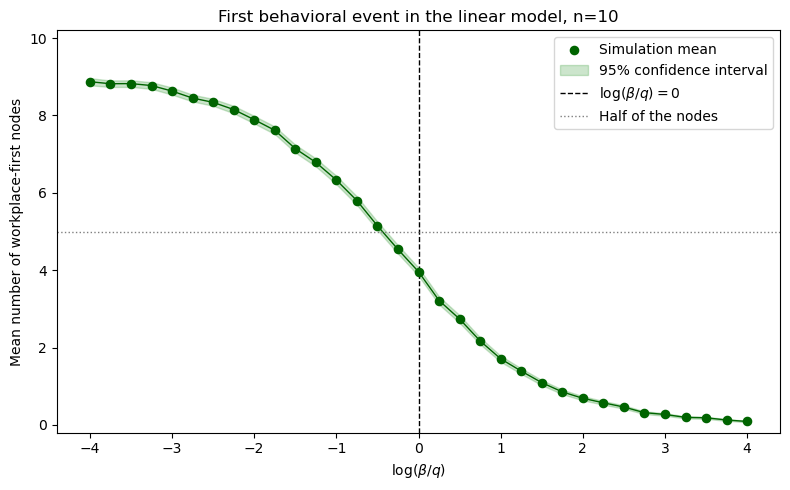


Final results
log(beta/q) =  -4.00, mean =  8.872, 95% CI = [ 8.780,  8.964], unresolved =  0.232
log(beta/q) =  -3.75, mean =  8.820, 95% CI = [ 8.735,  8.905], unresolved =  0.221
log(beta/q) =  -3.50, mean =  8.823, 95% CI = [ 8.737,  8.909], unresolved =  0.215
log(beta/q) =  -3.25, mean =  8.773, 95% CI = [ 8.686,  8.860], unresolved =  0.210
log(beta/q) =  -3.00, mean =  8.630, 95% CI = [ 8.538,  8.722], unresolved =  0.240
log(beta/q) =  -2.75, mean =  8.449, 95% CI = [ 8.362,  8.536], unresolved =  0.254
log(beta/q) =  -2.50, mean =  8.339, 95% CI = [ 8.249,  8.429], unresolved =  0.267
log(beta/q) =  -2.25, mean =  8.153, 95% CI = [ 8.057,  8.249], unresolved =  0.308
log(beta/q) =  -2.00, mean =  7.891, 95% CI = [ 7.793,  7.989], unresolved =  0.342
log(beta/q) =  -1.75, mean =  7.617, 95% CI = [ 7.519,  7.715], unresolved =  0.348
log(beta/q) =  -1.50, mean =  7.143, 95% CI = [ 7.040,  7.246], unresolved =  0.487
log(beta/q) =  -1.25, mean =  6.787, 95% CI = [ 6.684,  6.890

In [3]:

import os
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor



N_PROCESSES = 100
N_NODES = 10
N_REPETITIONS = 1000
N_BATCHES_PER_RATIO = 100
LAMBDA_WORKPLACE = 0.5
MAX_STEPS = 100_000
MASTER_SEED = 2026


def proportion_same_opinion(node, group, opinions):
    same = sum(
        opinions[j] == opinions[node]
        for j in group
    )

    return same / len(group)


def simulate_once(
    log_ratio,
    n,
    lambda_workplace,
    max_steps,
    rng
):
    ratio = np.exp(log_ratio)

    beta = ratio / (1.0 + ratio)
    q = 1.0 / (1.0 + ratio)

    household_size = n // 2

    households = [
        list(range(0, household_size)),
        list(range(household_size, n))
    ]

    permutation = rng.permutation(n)

    workplaces = [
        list(permutation[:household_size]),
        list(permutation[household_size:])
    ]

    workplace_of = np.empty(n, dtype=int)

    for workplace_index, workplace in enumerate(workplaces):
        for node in workplace:
            workplace_of[node] = workplace_index

    opinions = np.array(
        [0] * household_size
        + [1] * household_size
    )

    rng.shuffle(opinions)

    # Event codes:
    # 0 means no event yet
    # 1 means opinion change first
    # 2 means workplace change first
    first_event = np.zeros(n, dtype=np.int8)

    for step in range(max_steps):
        node = rng.integers(n)

        household_index = node // household_size
        household = households[household_index]

        workplace_index = workplace_of[node]
        workplace = workplaces[workplace_index]

        h = proportion_same_opinion(
            node,
            household,
            opinions
        )

        w = proportion_same_opinion(
            node,
            workplace,
            opinions
        )

        a = (
            h + lambda_workplace * w
        ) / (
            1.0 + lambda_workplace
        )

        opinion_change_probability = beta * (1.0 - a)

        if rng.random() < opinion_change_probability:
            opinions[node] = 1 - opinions[node]

            if first_event[node] == 0:
                first_event[node] = 1

        else:
            workplace_change_probability = q * (1.0 - w)

            if rng.random() < workplace_change_probability:
                candidate_workplaces = []

                for candidate_index, candidate in enumerate(workplaces):
                    if candidate_index == workplace_index:
                        continue

                    if len(candidate) == 0:
                        continue

                    same = sum(
                        opinions[j] == opinions[node]
                        for j in candidate
                    )

                    proportion = same / len(candidate)

                    if proportion > 0.5:
                        candidate_workplaces.append(candidate_index)

                if len(candidate_workplaces) == 0:
                    candidate_workplaces = [
                        candidate_index
                        for candidate_index in range(len(workplaces))
                        if candidate_index != workplace_index
                    ]

                if len(candidate_workplaces) > 0:
                    new_index = rng.choice(candidate_workplaces)

                    workplaces[workplace_index].remove(node)
                    workplaces[new_index].append(node)

                    workplace_of[node] = new_index

                    if first_event[node] == 0:
                        first_event[node] = 2

        if np.all(first_event != 0):
            break

    workplace_first = np.sum(first_event == 2)
    opinion_first = np.sum(first_event == 1)
    unresolved = np.sum(first_event == 0)

    return workplace_first, opinion_first, unresolved


def simulate_batch(task):
    log_ratio = task["log_ratio"]
    repetitions = task["repetitions"]
    seed = task["seed"]

    rng = np.random.default_rng(seed)

    workplace_first_counts = np.empty(
        repetitions,
        dtype=np.int16
    )

    unresolved_counts = np.empty(
        repetitions,
        dtype=np.int16
    )

    for repetition in range(repetitions):
        workplace_first, opinion_first, unresolved = simulate_once(
            log_ratio=log_ratio,
            n=N_NODES,
            lambda_workplace=LAMBDA_WORKPLACE,
            max_steps=MAX_STEPS,
            rng=rng
        )

        workplace_first_counts[repetition] = workplace_first
        unresolved_counts[repetition] = unresolved

    return {
        "ratio_index": task["ratio_index"],
        "batch_index": task["batch_index"],
        "counts": workplace_first_counts,
        "unresolved": unresolved_counts
    }


def divide_repetitions(total_repetitions, number_of_batches):
    base_size = total_repetitions // number_of_batches
    remainder = total_repetitions % number_of_batches

    batch_sizes = []

    for batch_index in range(number_of_batches):
        size = base_size

        if batch_index < remainder:
            size += 1

        if size > 0:
            batch_sizes.append(size)

    return batch_sizes


def create_tasks(log_ratios):
    number_of_ratios = len(log_ratios)

    batch_sizes = divide_repetitions(
        total_repetitions=N_REPETITIONS,
        number_of_batches=N_BATCHES_PER_RATIO
    )

    number_of_tasks = number_of_ratios * len(batch_sizes)

    seed_sequence = np.random.SeedSequence(MASTER_SEED)
    child_sequences = seed_sequence.spawn(number_of_tasks)

    tasks = []
    seed_index = 0

    for ratio_index, log_ratio in enumerate(log_ratios):
        for batch_index, batch_size in enumerate(batch_sizes):
            child_seed = child_sequences[seed_index]

            generated_seed = child_seed.generate_state(
                1,
                dtype=np.uint64
            )[0]

            task = {
                "ratio_index": ratio_index,
                "batch_index": batch_index,
                "log_ratio": float(log_ratio),
                "repetitions": batch_size,
                "seed": int(generated_seed)
            }

            tasks.append(task)
            seed_index += 1

    return tasks


def run_parallel_experiment(log_ratios):
    tasks = create_tasks(log_ratios)

    counts_by_ratio = [
        []
        for ratio_index in range(len(log_ratios))
    ]

    unresolved_by_ratio = [
        []
        for ratio_index in range(len(log_ratios))
    ]

    print(f"Number of parameter values: {len(log_ratios)}")
    print(f"Repetitions per parameter value: {N_REPETITIONS}")
    print(f"Number of parallel processes: {N_PROCESSES}")
    print(f"Total simulation runs: {len(log_ratios) * N_REPETITIONS}")
    print(f"Number of submitted batches: {len(tasks)}")

    with ProcessPoolExecutor(
        max_workers=N_PROCESSES
    ) as executor:
        results_iterator = executor.map(
            simulate_batch,
            tasks,
            chunksize=1
        )

        for completed_batches, batch_result in enumerate(
            results_iterator,
            start=1
        ):
            ratio_index = batch_result["ratio_index"]

            counts_by_ratio[ratio_index].append(
                batch_result["counts"]
            )

            unresolved_by_ratio[ratio_index].append(
                batch_result["unresolved"]
            )

            if completed_batches % 100 == 0:
                print(
                    f"Completed batches: "
                    f"{completed_batches}/{len(tasks)}"
                )

    results = []

    for ratio_index, log_ratio in enumerate(log_ratios):
        counts = np.concatenate(
            counts_by_ratio[ratio_index]
        )

        unresolved = np.concatenate(
            unresolved_by_ratio[ratio_index]
        )

        mean_count = counts.mean()
        standard_deviation = counts.std(ddof=1)

        standard_error = (
            standard_deviation
            / np.sqrt(len(counts))
        )

        confidence_distance = 1.96 * standard_error

        result = {
            "log_ratio": log_ratio,
            "mean": mean_count,
            "standard_deviation": standard_deviation,
            "standard_error": standard_error,
            "lower": mean_count - confidence_distance,
            "upper": mean_count + confidence_distance,
            "mean_unresolved": unresolved.mean(),
            "repetitions": len(counts)
        }

        results.append(result)

    return results


def save_results(results, output_filename):
    output = np.array(
        [
            [
                result["log_ratio"],
                result["mean"],
                result["standard_deviation"],
                result["standard_error"],
                result["lower"],
                result["upper"],
                result["mean_unresolved"],
                result["repetitions"]
            ]
            for result in results
        ]
    )

    header = (
        "log_beta_over_q,"
        "mean_workplace_first,"
        "standard_deviation,"
        "standard_error,"
        "confidence_interval_lower,"
        "confidence_interval_upper,"
        "mean_unresolved,"
        "repetitions"
    )

    np.savetxt(
        output_filename,
        output,
        delimiter=",",
        header=header,
        comments=""
    )


def make_plot(results, output_filename):
    x = np.array(
        [result["log_ratio"] for result in results]
    )

    mean = np.array(
        [result["mean"] for result in results]
    )

    lower = np.array(
        [result["lower"] for result in results]
    )

    upper = np.array(
        [result["upper"] for result in results]
    )

    plt.figure(figsize=(8, 5))

    plt.scatter(
        x,
        mean,
        color="darkgreen",
        s=35,
        zorder=3,
        label="Simulation mean"
    )

    plt.plot(
        x,
        mean,
        color="darkgreen",
        linewidth=1
    )

    plt.fill_between(
        x,
        lower,
        upper,
        color="green",
        alpha=0.2,
        label="95% confidence interval"
    )

    plt.axvline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=1,
        label=r"$\log(\beta/q)=0$"
    )

    plt.axhline(
        N_NODES / 2,
        color="gray",
        linestyle=":",
        linewidth=1,
        label="Half of the nodes"
    )

    plt.xlabel(r"$\log(\beta/q)$")
    plt.ylabel("Mean number of workplace-first nodes")

    plt.title(
        f"First behavioral event in the linear model, "
        f"n={N_NODES}"
    )

    plt.ylim(-0.2, N_NODES + 0.2)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


def main():
    log_ratios = np.linspace(
        -4.0,
        4.0,
        33
    )

    results = run_parallel_experiment(log_ratios)

    save_results(
        results,
        "workplace_first_results.csv"
    )

    make_plot(
        results,
        "workplace_first_parallel.png"
    )

    print("\nFinal results")

    for result in results:
        print(
            f"log(beta/q) = {result['log_ratio']:6.2f}, "
            f"mean = {result['mean']:6.3f}, "
            f"95% CI = "
            f"[{result['lower']:6.3f}, "
            f"{result['upper']:6.3f}], "
            f"unresolved = {result['mean_unresolved']:6.3f}"
        )

    print("\nSaved files:")
    print("workplace_first_results.csv")
    print("workplace_first_parallel.png")


if __name__ == "__main__":
    mp.freeze_support()
    main()